In [ ]:
import kagglehub
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.


In [ ]:
import pandas as pd
df = pd.read_csv(path + "/diabetes_prediction_dataset.csv")
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [ ]:
# 1. First 5 rows
print("First 5 Rows:")
print(df.head())

First 5 Rows:
   gender   age  hypertension  heart_disease smoking_history    bmi  \
0  Female  80.0             0              1           never  25.19   
1  Female  54.0             0              0         No Info  27.32   
2    Male  28.0             0              0           never  27.32   
3  Female  36.0             0              0         current  23.45   
4    Male  76.0             1              1         current  20.14   

   HbA1c_level  blood_glucose_level  diabetes  
0          6.6                  140         0  
1          6.6                   80         0  
2          5.7                  158         0  
3          5.0                  155         0  
4          4.8                  155         0  


In [ ]:
# 2. Last 5 rows
print("\nLast 5 Rows:")
print(df.tail())


Last 5 Rows:
       gender   age  hypertension  heart_disease smoking_history    bmi  \
99995  Female  80.0             0              0         No Info  27.32   
99996  Female   2.0             0              0         No Info  17.37   
99997    Male  66.0             0              0          former  27.83   
99998  Female  24.0             0              0           never  35.42   
99999  Female  57.0             0              0         current  22.43   

       HbA1c_level  blood_glucose_level  diabetes  
99995          6.2                   90         0  
99996          6.5                  100         0  
99997          5.7                  155         0  
99998          4.0                  100         0  
99999          6.6                   90         0  


In [ ]:
# 4. Column names
print("\nColumn Names:")
print(df.columns.tolist())


Column Names:
['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes']


In [ ]:
# 5. Data types
print("\nData Types:")
print(df.dtypes)


Data Types:
gender                  object
age                    float64
hypertension             int64
heart_disease            int64
smoking_history         object
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int64
diabetes                 int64
dtype: object


In [ ]:
# 6. Dataset information
print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


In [ ]:
# 8. Duplicate records
print("\nNumber of Duplicate Records:")
print(df.duplicated().sum())


Number of Duplicate Records:
3854


In [ ]:
print(df.isnull().sum())

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64


In [ ]:
df.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,41.885856,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,22.516840,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,0.080000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,24.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,43.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,60.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,80.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000


In [ ]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, classification_report

In [ ]:
X = df.drop(columns=['diabetes'])
y = df['diabetes']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# If X_train has been overwritten as a numpy array, recreate X_train and X_test from df
if not isinstance(X_train, pd.DataFrame):
    X = df.drop(columns=['diabetes'])
    y = df['diabetes']
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

X_train_encoded = pd.get_dummies(X_train, columns=['gender', 'smoking_history'], drop_first=True)
X_test_encoded = pd.get_dummies(X_test, columns=['gender', 'smoking_history'], drop_first=True)

X_train_encoded, X_test_encoded = X_train_encoded.align(X_test_encoded, join='left', axis=1, fill_value=0)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_encoded)
X_test_scaled = scaler.transform(X_test_encoded)

### Logistic Regression

In [ ]:
# Model
model = LogisticRegression()

# Train using scaled data
model.fit(X_train_scaled, y_train)

# Prediction using scaled data
y_pred = model.predict(X_test_scaled)

# Result
print("Logistic Regression")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Logistic Regression
Accuracy: 0.9605
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     18300
           1       0.86      0.64      0.73      1700

    accuracy                           0.96     20000
   macro avg       0.91      0.82      0.86     20000
weighted avg       0.96      0.96      0.96     20000



In [ ]:
# Train the model using the preprocessed and scaled data
model.fit(X_train_scaled, y_train)

LogisticRegression()

### KNN

In [ ]:
# Model
model = KNeighborsClassifier(n_neighbors=5)

# Train using scaled data
model.fit(X_train_scaled, y_train)

# Prediction using scaled data
y_pred = model.predict(X_test_scaled)

# Result
print("KNN")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

KNN
Accuracy: 0.9605
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     18300
           1       0.88      0.62      0.73      1700

    accuracy                           0.96     20000
   macro avg       0.92      0.81      0.85     20000
weighted avg       0.96      0.96      0.96     20000



In [ ]:
# Train the model using preprocessed and scaled training data
model.fit(X_train_scaled, y_train)

KNeighborsClassifier()

### Decision Tree

In [ ]:
# Model
model = DecisionTreeClassifier(random_state=42)

# Train using scaled data
model.fit(X_train_scaled, y_train)

# Prediction using scaled data
y_pred = model.predict(X_test_scaled)

# Result
print("Decision Tree")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Decision Tree
Accuracy: 0.9512
              precision    recall  f1-score   support

           0       0.98      0.97      0.97     18300
           1       0.70      0.74      0.72      1700

    accuracy                           0.95     20000
   macro avg       0.84      0.86      0.85     20000
weighted avg       0.95      0.95      0.95     20000



In [ ]:
# Train the model using preprocessed and scaled training data to avoid categorical string errors
model.fit(X_train_scaled, y_train)

DecisionTreeClassifier(random_state=42)

### Random Forest

In [ ]:
# Model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train using scaled numerical data to avoid string-to-float conversion errors
model.fit(X_train_scaled, y_train)

# Prediction using scaled numerical data
y_pred = model.predict(X_test_scaled)

# Result
print("Random Forest")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Random Forest
Accuracy: 0.9703
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     18300
           1       0.95      0.69      0.80      1700

    accuracy                           0.97     20000
   macro avg       0.96      0.84      0.89     20000
weighted avg       0.97      0.97      0.97     20000



In [ ]:
model.fit(X_train_scaled, y_train)

RandomForestClassifier(random_state=42)

### SVM

In [ ]:
# Model
model = SVC()

# Train using scaled data to avoid string-to-float errors
model.fit(X_train_scaled, y_train)

# Prediction using scaled data
y_pred = model.predict(X_test_scaled)

# Result
print("SVM")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

SVM
Accuracy: 0.9636
              precision    recall  f1-score   support

           0       0.96      1.00      0.98     18300
           1       0.97      0.59      0.73      1700

    accuracy                           0.96     20000
   macro avg       0.96      0.80      0.86     20000
weighted avg       0.96      0.96      0.96     20000



In [ ]:
model.fit(X_train_scaled, y_train)

SVC()

In [ ]:
# Define the models dictionary containing the classifiers
models = {
    "Logistic Regression": LogisticRegression(),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM": SVC()
}

results = {}

for name, model in models.items():
    # Use the preprocessed, scaled numerical datasets
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)

    accuracy = accuracy_score(y_test, y_pred)
    results[name] = accuracy

    print(name)
    print("Accuracy:", round(accuracy * 100, 2), "%")
    print(classification_report(y_test, y_pred))
    print("-" * 55)

Logistic Regression
Accuracy: 96.05 %
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     18300
           1       0.86      0.64      0.73      1700

    accuracy                           0.96     20000
   macro avg       0.91      0.82      0.86     20000
weighted avg       0.96      0.96      0.96     20000

-------------------------------------------------------
KNN
Accuracy: 96.05 %
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     18300
           1       0.88      0.62      0.73      1700

    accuracy                           0.96     20000
   macro avg       0.92      0.81      0.85     20000
weighted avg       0.96      0.96      0.96     20000

-------------------------------------------------------
Decision Tree
Accuracy: 95.12 %
              precision    recall  f1-score   support

           0       0.98      0.97      0.97     18300
           1       0.70      0.74

In [ ]:
print("\nModel Comparison")

for name, accuracy in results.items():
    print(name, ":", round(accuracy * 100, 2), "%")


Model Comparison
Logistic Regression : 96.05 %
KNN : 96.05 %
Decision Tree : 95.12 %
Random Forest : 97.03 %
SVM : 96.36 %


In [ ]:
best_model = max(results, key=results.get)

print("Best Model:", best_model)
print("Best Accuracy:", round(results[best_model] * 100, 2), "%")

Best Model: Random Forest
Best Accuracy: 97.03 %


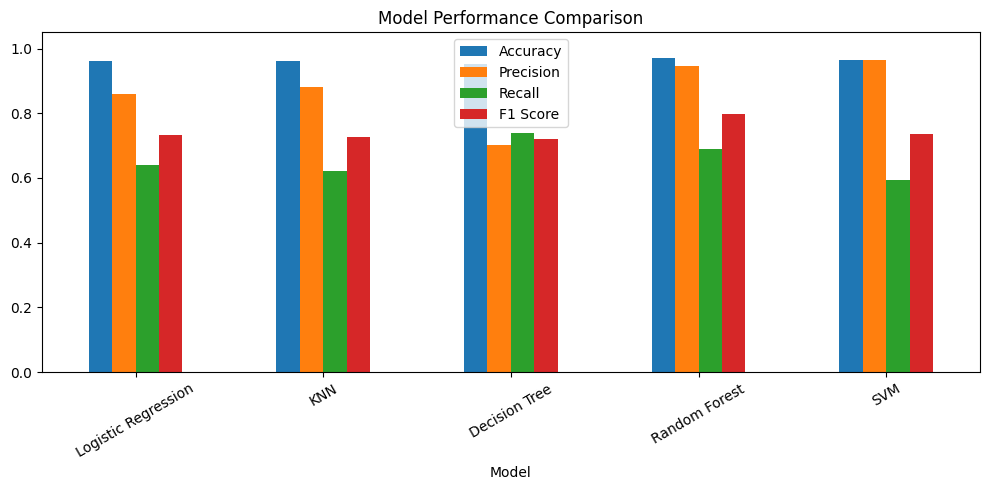

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []

for name, model in models.items():
    y_pred = model.predict(X_test_scaled)
    results.append([
        name,
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0)
    ])

df = pd.DataFrame(results, columns=[
    "Model", "Accuracy", "Precision", "Recall", "F1 Score"
])

df.set_index("Model").plot(kind="bar", figsize=(10, 5))
plt.title("Model Performance Comparison")
plt.ylim(0, 1.05)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

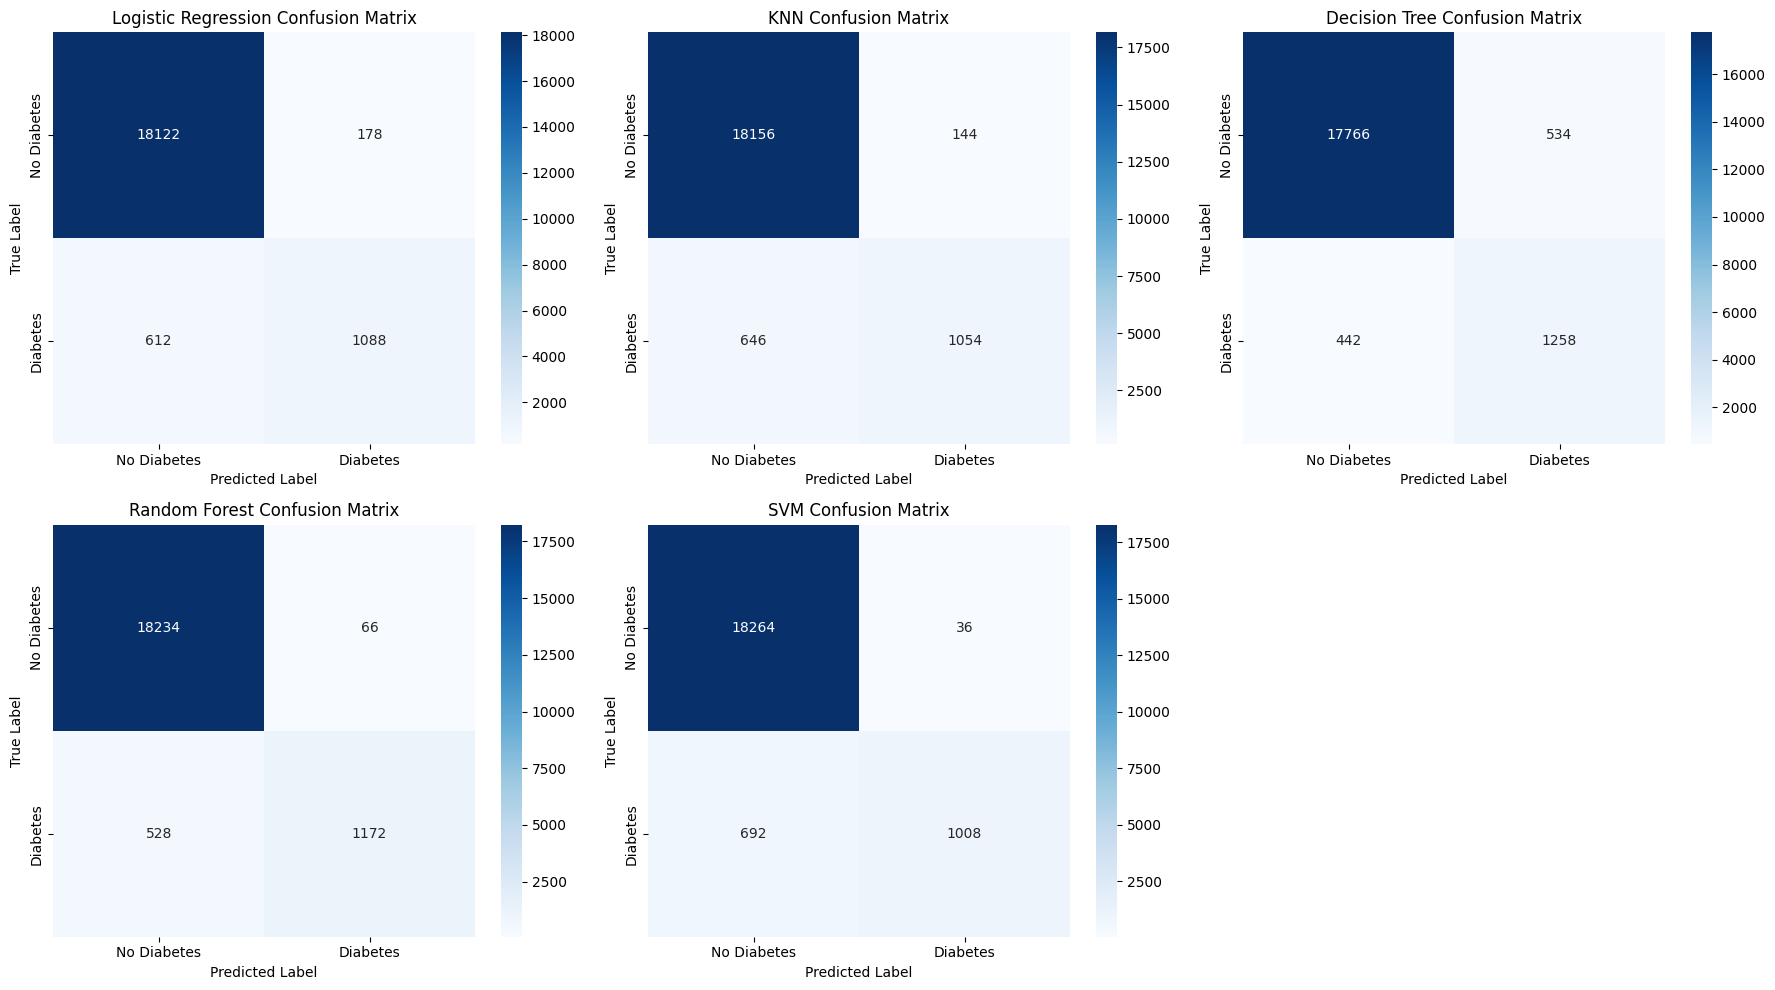

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Set up a grid for Confusion Matrices
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

for i, (name, model) in enumerate(models.items()):
    # Generate predictions
    y_pred = model.predict(X_test_scaled)
    cm = confusion_matrix(y_test, y_pred)

    # Plot heatmaps
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=['No Diabetes', 'Diabetes'],
                yticklabels=['No Diabetes', 'Diabetes'])
    axes[i].set_title(f"{name} Confusion Matrix")
    axes[i].set_xlabel("Predicted Label")
    axes[i].set_ylabel("True Label")

# Remove empty subplot in the grid (since we have 5 models for 6 subplots)
if len(axes) > len(models):
    fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

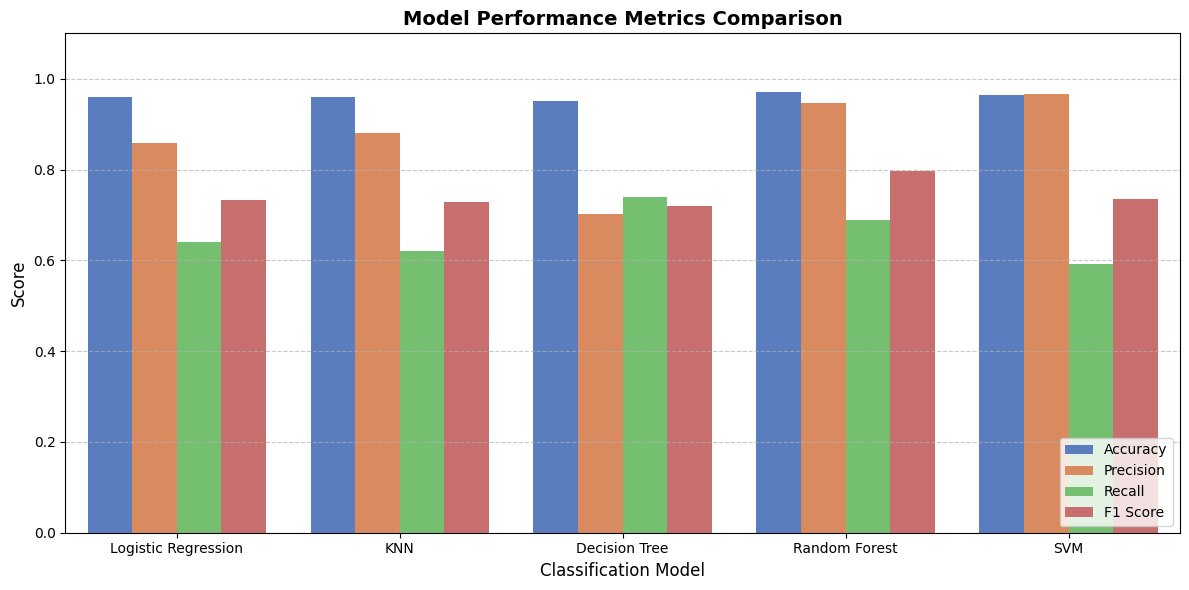

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Gather metrics
metrics_list = []
for name, model in models.items():
    y_pred = model.predict(X_test_scaled)
    metrics_list.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0)
    })

# Convert to DataFrame
df_metrics = pd.DataFrame(metrics_list)

# Melt the DataFrame for Seaborn plotting
df_melted = df_metrics.melt(id_vars="Model", var_name="Metric", value_name="Score")

# Plot using Seaborn
plt.figure(figsize=(12, 6))
sns.barplot(x="Model", y="Score", hue="Metric", data=df_melted, palette="muted")

plt.title("Model Performance Metrics Comparison", fontsize=14, fontweight='bold')
plt.xlabel("Classification Model", fontsize=12)
plt.ylabel("Score", fontsize=12)
plt.ylim(0, 1.1)
plt.legend(loc="lower right")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

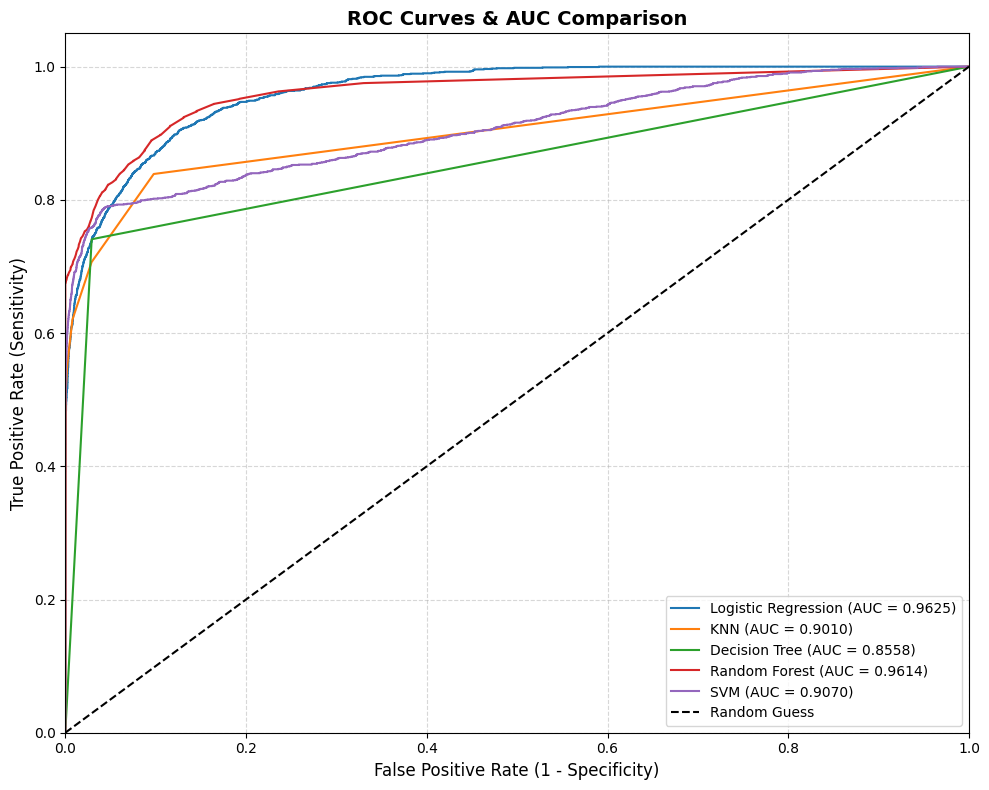

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Set up the ROC Curve Plot
plt.figure(figsize=(10, 8))

for name, model in models.items():
    if hasattr(model, "predict_proba"):
        y_probs = model.predict_proba(X_test_scaled)[:, 1]
    elif hasattr(model, "decision_function"):
        y_probs = model.decision_function(X_test_scaled)
    else:
        continue

    fpr, tpr, _ = roc_curve(y_test, y_probs)
    auc_score = roc_auc_score(y_test, y_probs)

    # Plot the curve with AUC score in the legend
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_score:.4f})")

plt.plot([0, 1], [0, 1], 'k--', label="Random Guess")

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity)', fontsize=12)
plt.title('ROC Curves & AUC Comparison', fontsize=14, fontweight='bold')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
import joblib

# Save the trained model
joblib.dump(best_model, "best_model.pkl")

# Save the fitted scaler
joblib.dump(scaler, "scaler.pkl")

# Save the feature columns
joblib.dump(list(X_train_encoded.columns), "feature_columns.pkl")

print("All files saved successfully!")

All files saved successfully!


In [ ]:
import joblib
joblib.dump(best_model, "best_model.pkl")
print("Best model (Random Forest) saved successfully!")

Best model (Random Forest) saved successfully!


In [ ]:
from sklearn.preprocessing import OneHotEncoder
import joblib

categorical_columns = ["gender", "smoking_history"]
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
encoder.fit(X_train[categorical_columns])

joblib.dump(encoder, "encoder.pkl")

print("Diabetes Categorical Encoder saved successfully!")

Diabetes Categorical Encoder saved successfully!


In [ ]:
joblib.dump(encoder, "encoder.pkl")

['encoder.pkl']